In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
df = pd.read_csv("insurance.csv")

In [3]:
# Encode categorical data
df["smoker"] = df["smoker"].map({
    "no": 0,
    "yes": 1
})

In [4]:
# Selecting features and target
X = df[["age", "bmi", "children", "smoker"]]
y = df["charges"]

In [5]:
# Split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [6]:
# Calculate mean and standard deviation from training data only
X_mean = X_train.mean()
X_std = X_train.std()

# Standardization formula:
# z = (x - mean) / standard deviation

X_train_scaled = (X_train - X_mean) / X_std
X_test_scaled = (X_test - X_mean) / X_std

In [7]:
# Selected age as the only feature for simple linear regression
X_simple = df[["age"]]

#splitting the data and giving test size =  20% and setting seed to 42 so the prediction always same 
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

simple_model = LinearRegression()
simple_model.fit(X_train_s, y_train_s)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[240.6]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['age']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3877
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [8]:
y_pred_s = simple_model.predict(X_test_s)

In [9]:
print("SIMPLE LINEAR REGRESSION")
print("Coefficient:", simple_model.coef_[0])
print("Intercept:", simple_model.intercept_)
print("MSE:", mean_squared_error(y_test_s, y_pred_s))
print("R² Score:", r2_score(y_test_s, y_pred_s))

SIMPLE LINEAR REGRESSION
Coefficient: 240.59655978877493
Intercept: 3876.928684191691
MSE: 135983957.4805469
R² Score: 0.12408973539501944


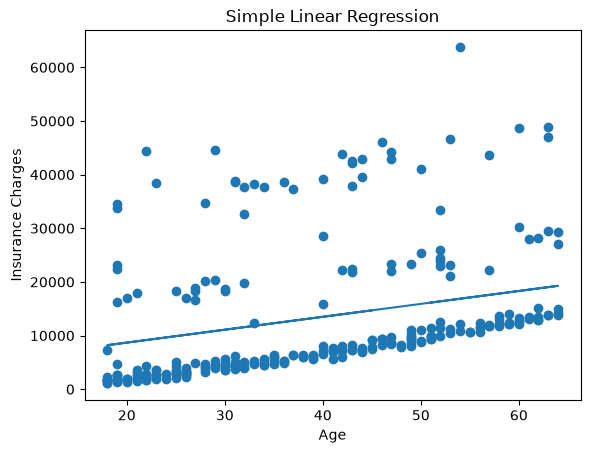

In [10]:
plt.scatter(X_test_s, y_test_s)
plt.plot(X_test_s, y_pred_s)

plt.xlabel("Age")
plt.ylabel("Insurance Charges")
plt.title("Simple Linear Regression")
plt.show()


In [11]:
multiple_model = LinearRegression()

# Train the model using all selected standardized features
# (age, bmi, children and smoker)
multiple_model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[3618.01,1979.35, 519.47,9563.79]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['age','bmi','children','smoker']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.335e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [12]:
# Predict the data
y_pred = multiple_model.predict(X_test_scaled)

# Results
print("\nMULTIPLE LINEAR REGRESSION")
print("Intercept:", multiple_model.intercept_)
print("MSE:", mean_squared_error(y_test, y_pred))
print("R² Score:", r2_score(y_test, y_pred))


MULTIPLE LINEAR REGRESSION
Intercept: 13346.089736364487
MSE: 33981653.95019775
R² Score: 0.7811147722517887


In [13]:
# Display the coefficient of each feature
# The coefficients show how each feature affects the predicted charges
print("\nREGRESSION COEFFICIENTS")

for feature, coefficient in zip(X.columns, multiple_model.coef_):
    print(feature, ":", coefficient)



REGRESSION COEFFICIENTS
age : 3618.009229997087
bmi : 1979.3455762411654
children : 519.4680862036113
smoker : 9563.793264873773


In [14]:
new_person = pd.DataFrame(
    [[30, 25.5, 1, 0]],
    columns=X.columns
)

# Standardize new person's values using training mean and std
new_person_scaled = (new_person - X_mean) / X_std

# Predict
prediction = multiple_model.predict(new_person_scaled)

print("\nPredicted Insurance Charges:", prediction[0])


Predicted Insurance Charges: 4374.086728284303


In [15]:
for feature, coefficient in zip(X.columns, multiple_model.coef_):
    print(feature, ":", coefficient)

age : 3618.009229997087
bmi : 1979.3455762411654
children : 519.4680862036113
smoker : 9563.793264873773


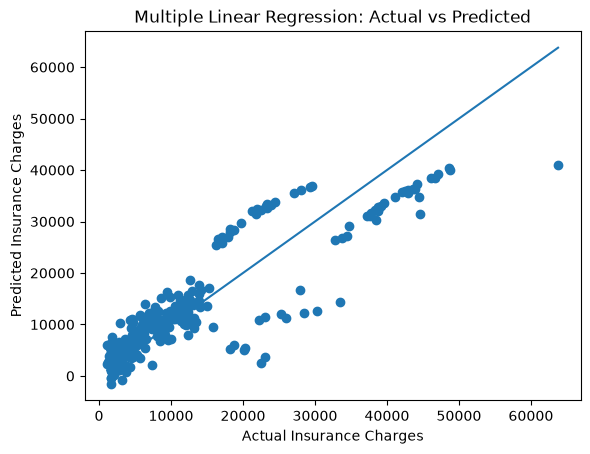

In [18]:
# Plot actual vs predicted insurance charges
plt.scatter(y_test, y_pred)

# Reference line: perfect predictions
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)

plt.xlabel("Actual Insurance Charges")
plt.ylabel("Predicted Insurance Charges")
plt.title("Multiple Linear Regression: Actual vs Predicted")

plt.show()